## Project Introduction

### Used Car Price Prediction

In this project, we have predicted the price of a used car using features such as brand, model, mileage, fuel type, accident history, engine details, transmission, and model year.

This is a regression problem because the target variable, price, is a continuous numerical value.

### Importing Libraries

We import the libraries required for data handling, visualization, preprocessing, model training and evaluation.

In [131]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Loading the Dataset

The training dataset contains the actual price of each car, while the test dataset does not contain the price.
We will use the training data to learn the relationship between the car features and price

In [132]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

In [133]:
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (3207, 14)
Test shape: (802, 13)


The training dataset contains the target variable `price`, while the test dataset does not.
The test dataset will be used only for final predictions.

## Understanding the Dataset

Before cleaning the data, we inspect the first few rows, column information and statistical summary.

In [134]:
train_df.head()

,id,brand,model,model_year,milage,fuel_type,ext_col,int_col,accident,clean_title,price,engine_displacement_l,engine_cylinders,transmission_type
0,1,Lexus,IS 300 Base,2018,"50,992 mi.",Gasoline,White,Gray,At least 1 accident or damage reported,Yes,"$28,000",3.5,6.0,Automatic
1,2,Chevrolet,Impala Base,2004,"64,500 mi.",Gasoline,Beige,Beige,None reported,Yes,"$5,900",3.4,6.0,Automatic
2,3,RAM,2500 SLT,2017,"86,000 mi.",Diesel,Gray,Gray,At least 1 accident or damage reported,Yes,"$41,000",6.7,6.0,Automatic
3,4,Mercedes-Benz,SL-Class SL 550,2013,"24,933 mi.",Gasoline,Silver,Red,At least 1 accident or damage reported,Yes,"$40,250",4.6,8.0,Other
4,5,Ford,Shelby GT350R Base,2018,"18,500 mi.",Gasoline,Blue,Black,At least 1 accident or damage reported,Yes,"$77,999",5.2,8.0,Manual


In [135]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3207 entries, 0 to 3206
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     3207 non-null   int64  
 1   brand                  3207 non-null   str    
 2   model                  3207 non-null   str    
 3   model_year             3207 non-null   int64  
 4   milage                 3207 non-null   str    
 5   fuel_type              3074 non-null   str    
 6   ext_col                3207 non-null   str    
 7   int_col                3207 non-null   str    
 8   accident               3115 non-null   str    
 9   clean_title            2725 non-null   str    
 10  price                  3207 non-null   str    
 11  engine_displacement_l  3032 non-null   float64
 12  engine_cylinders       2856 non-null   float64
 13  transmission_type      3207 non-null   str    
dtypes: float64(2), int64(2), str(10)
memory usage: 624.9 KB


In [136]:
train_df.describe()

,id,model_year,engine_displacement_l,engine_cylinders
count,3207.000000,3207.000000,3032.000000,2856.000000
mean,1604.000000,2015.476458,3.760587,6.220238
std,925.925483,6.136673,2.796765,1.731390
min,1.000000,1974.000000,1.000000,3.000000
25%,802.500000,2012.000000,2.500000,4.000000
50%,1604.000000,2017.000000,3.500000,6.000000
75%,2405.500000,2020.000000,4.700000,8.000000
max,3207.000000,2024.000000,75.000000,16.000000


## Checking Missing Values

We check the number of missing values in each column before deciding how to handle them.

In [137]:
train_df.isna().sum()

id                         0
brand                      0
model                      0
model_year                 0
milage                     0
fuel_type                133
ext_col                    0
int_col                    0
accident                  92
clean_title              482
price                      0
engine_displacement_l    175
engine_cylinders         351
transmission_type          0
dtype: int64

Some columns contain missing values.

We will handle numerical and categorical missing values separately after splitting the data into training and validation sets.

### Check Duplicate Rows

In [138]:
print("Duplicate rows:", train_df.duplicated().sum())

Duplicate rows: 0


## Cleaning the Target Variable

The price column is stored as text and contains $ signs and commas. We remove these characters and convert the column to a numerical data type.

In [139]:
train_df["price"] = (
    train_df["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

In [142]:
train_df["price"].describe()

count    3.207000e+03
mean     4.523930e+04
std      8.486586e+04
min      2.000000e+03
25%      1.700000e+04
50%      3.100000e+04
75%      4.990000e+04
max      2.954083e+06
Name: price, dtype: float64

The price column is now numerical and can be used as the regression target.

## Check Price Distribution

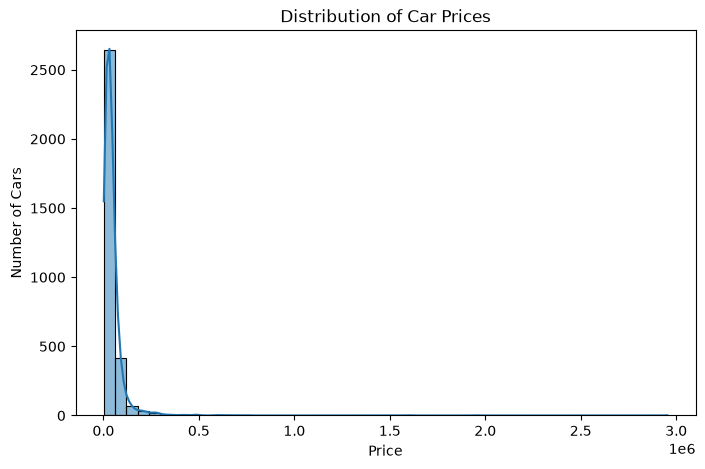

In [143]:
plt.figure(figsize=(8, 5))

sns.histplot(
    train_df["price"],
    bins=50,
    kde=True
)

plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of Cars")
plt.show()

The histogram shows the distribution of car prices.
It helps us identify whether the target is approximately symmetric or skewed and whether there are unusually high or low prices.

# Cleaning Mileage

The milage column is stored as text, for example 51,000 mi.
We remove the comma and mi. and convert the values into numerical form.

In [144]:
train_df["milage"] = (
    train_df["milage"]
    .str.replace(",", "", regex=False)
    .str.replace("mi.", "", regex=False)
    .str.strip()
    .astype(float)
)

test_df["milage"] = (
    test_df["milage"]
    .str.replace(",", "", regex=False)
    .str.replace("mi.", "", regex=False)
    .str.strip()
    .astype(float)
)

In [145]:
train_df[["milage", "price"]].head()

,milage,price
0,50992.0,28000.0
1,64500.0,5900.0
2,86000.0,41000.0
3,24933.0,40250.0
4,18500.0,77999.0


 Mileage is now numerical and can be used as a model feature.

## Mileage vs Price

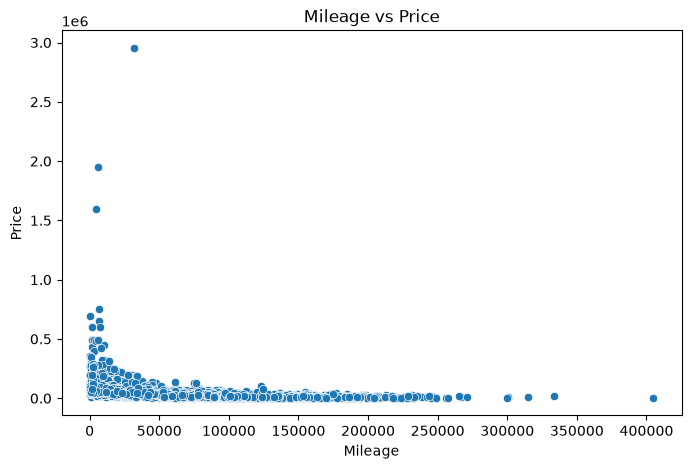

In [146]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=train_df,
    x="milage",
    y="price"
)

plt.title("Mileage vs Price")
plt.xlabel("Mileage")
plt.ylabel("Price")
plt.show()

This plot helps us understand the relationship between mileage and car price.
Mileage may influence the value of a used car because cars with higher usage can have different market prices.

### Model Year vs Price

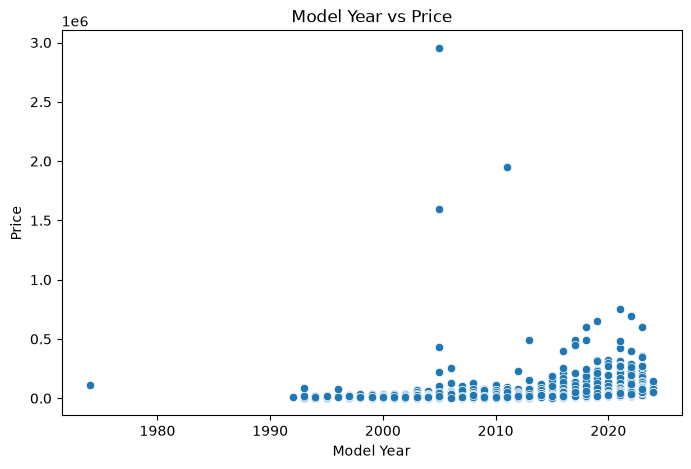

In [147]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=train_df,
    x="model_year",
    y="price"
)

plt.title("Model Year vs Price")
plt.xlabel("Model Year")
plt.ylabel("Price")
plt.show()

This plot helps us understand whether newer cars tend to have different prices compared with older cars.

### Check Categorical Cardinality

We check the number of unique values in categorical columns.
This is important because model and brand can have many unique values.
Using one-hot encoding directly on high-cardinality columns can create a very large number of features.

In [148]:
categorical_check_columns = [
    "brand",
    "model",
    "fuel_type",
    "ext_col",
    "int_col",
    "accident",
    "clean_title",
    "transmission_type"
]

for column in categorical_check_columns:
    print(column, ":", train_df[column].nunique())

brand : 57
model : 1673
fuel_type : 7
ext_col : 275
int_col : 135
accident : 2
clean_title : 1
transmission_type : 3


The number of unique values differs considerably across the categorical columns.

brand and especially model have relatively high cardinality, so we will use frequency encoding for them instead of directly applying one-hot encoding.

## Check Missing Categorical Values

In [149]:
categorical_check_columns = [
    "fuel_type",
    "ext_col",
    "int_col",
    "accident",
    "clean_title",
    "transmission_type"
]

for column in categorical_check_columns:
    print(column, ":", train_df[column].isna().sum())

fuel_type : 133
ext_col : 0
int_col : 0
accident : 92
clean_title : 482
transmission_type : 0


Several categorical columns contain missing values.

Instead of treating a missing categorical value as an existing category such as `No`, we will preserve the missing information using a separate Missing category.

## Feature Engineering — Car Age

In [150]:
current_year = 2026

train_df["car_age"] = current_year - train_df["model_year"]
test_df["car_age"] = current_year - test_df["model_year"]

In [151]:
train_df[["model_year", "car_age"]].head()

,model_year,car_age
0,2018,8
1,2004,22
2,2017,9
3,2013,13
4,2018,8


## Separate Features and Target

price is our target variable.
The id column is only an identifier, so we do not use it as a feature.

In [152]:
X = train_df.drop(columns=["price", "id"])
y = train_df["price"]

X_test = test_df.drop(columns=["id"])

## Train-Validation Split

We split the labelled training data into:

- 80% training data
- 20% validation data

The model learns from the training portion, while the validation portion is used to evaluate the model before making predictions on the actual test dataset.

In [153]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

## Frequency Encoding for Brand and Model

`brand` and `model` have many unique categories.
Frequency encoding replaces each category with the number of times it occurs in the training data.
    
For example:
Toyota → 200  
BMW → 80
    
We calculate these frequencies using only the training data.
This is important because validation and test information should not be used to learn the preprocessing rules.

In [154]:
brand_frequency = X_train["brand"].value_counts()
model_frequency = X_train["model"].value_counts()

In [155]:
X_train["brand_frequency"] = X_train["brand"].map(brand_frequency)
X_valid["brand_frequency"] = X_valid["brand"].map(brand_frequency)
X_test["brand_frequency"] = X_test["brand"].map(brand_frequency)

X_train["model_frequency"] = X_train["model"].map(model_frequency)
X_valid["model_frequency"] = X_valid["model"].map(model_frequency)
X_test["model_frequency"] = X_test["model"].map(model_frequency)

In [156]:
X_train = X_train.drop(columns=["brand", "model"])
X_valid = X_valid.drop(columns=["brand", "model"])
X_test = X_test.drop(columns=["brand", "model"])

The original high-cardinality `brand` and `model` columns have been replaced with numerical frequency features.

If a category appears in validation or test data but was not present in training data, its frequency becomes missing. These values will be handled along with the other numerical missing values.

## Define Numerical and Categorical Features

In [157]:
numeric_columns = [
    "model_year",
    "milage",
    "engine_displacement_l",
    "engine_cylinders",
    "car_age",
    "brand_frequency",
    "model_frequency"
]

categorical_columns = [
    "fuel_type",
    "ext_col",
    "int_col",
    "accident",
    "clean_title",
    "transmission_type"
]

## Handling Numerical Missing Values Using Pandas

For each numerical column, we calculate the median using only the training data.
Then we use the same median for the training, validation and test data.
This prevents validation or test data from influencing the preprocessing.

In [158]:
for column in numeric_columns:

    median_value = X_train[column].median()

    X_train[column] = X_train[column].fillna(median_value)
    X_valid[column] = X_valid[column].fillna(median_value)
    X_test[column] = X_test[column].fillna(median_value)

## Handle Categorical Missing Values

For categorical columns, we replace missing values with `"Missing"`.
This is preferable here because the instructions specifically mention that missing values, especially in `clean_title`, should not automatically be treated as `"No"`.

In [159]:
for column in categorical_columns:

    X_train[column] = X_train[column].fillna("Missing")
    X_valid[column] = X_valid[column].fillna("Missing")
    X_test[column] = X_test[column].fillna("Missing")

In [160]:
print("Remaining numerical missing values:")
print(X_train[numeric_columns].isna().sum())

print("\nRemaining categorical missing values:")
print(X_train[categorical_columns].isna().sum())

Remaining numerical missing values:
model_year               0
milage                   0
engine_displacement_l    0
engine_cylinders         0
car_age                  0
brand_frequency          0
model_frequency          0
dtype: int64

Remaining categorical missing values:
fuel_type            0
ext_col              0
int_col              0
accident             0
clean_title          0
transmission_type    0
dtype: int64


The missing values in the selected numerical and categorical features have now been handled.

## One-Hot Encoding

The remaining categorical variables have relatively fewer unique categories.
We use one-hot encoding to convert these categorical values into numerical 0/1 columns.
The encoder is fitted only on the training data and then applied to validation and test data.

In [161]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [162]:
X_train_categorical = encoder.fit_transform(
    X_train[categorical_columns]
)

X_valid_categorical = encoder.transform(
    X_valid[categorical_columns]
)

X_test_categorical = encoder.transform(
    X_test[categorical_columns]
)

`handle_unknown="ignore"` makes sure that if a category appears in validation or test data that was not present during training, the encoder does not produce an error.

## Prepare Numerical Features

In [163]:
X_train_numeric = X_train[numeric_columns].values
X_valid_numeric = X_valid[numeric_columns].values
X_test_numeric = X_test[numeric_columns].values

## Combine Numerical and Categorical Features

The numerical features are already numerical, while the categorical features have been converted into numerical columns using one-hot encoding.

We combine both parts to create the final feature matrices.

In [164]:
X_train_final = np.hstack([
    X_train_numeric,
    X_train_categorical
])

X_valid_final = np.hstack([
    X_valid_numeric,
    X_valid_categorical
])

X_test_final = np.hstack([
    X_test_numeric,
    X_test_categorical
])

In [165]:
print("Training shape:", X_train_final.shape)
print("Validation shape:", X_valid_final.shape)
print("Test shape:", X_test_final.shape)

Training shape: (2565, 386)
Validation shape: (642, 386)
Test shape: (802, 386)


The training, validation and test data now have the same feature structure and are ready for model training.

## Linear Regression Baseline

We first train a Linear Regression model.
A baseline model gives us a simple reference point against which we can compare the more flexible Random Forest model.

In [166]:
linear_model = LinearRegression()

linear_model.fit(
    X_train_final,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](386,)","[ 654.88, -0.33, -947.64,...,-7230.47,10711.19,-3480.72]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.307e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,386
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(48)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](386,)","[2659781.55, 4060. , 346.34,..., 0. , 0. , 0. ]"


In [167]:
linear_predictions = linear_model.predict(X_valid_final)

### Evaluating Linear Regression

We use three regression metrics:

- RMSE
- MAE
- R²

For RMSE and MAE, lower values are better.

For R², a higher value is generally better.

In [168]:
linear_rmse = np.sqrt(
    mean_squared_error(
        y_valid,
        linear_predictions
    )
)

linear_mae = mean_absolute_error(
    y_valid,
    linear_predictions
)

linear_r2 = r2_score(
    y_valid,
    linear_predictions
)

print("Linear Regression RMSE:", linear_rmse)
print("Linear Regression MAE:", linear_mae)
print("Linear Regression R²:", linear_r2)

Linear Regression RMSE: 121075.10330258342
Linear Regression MAE: 27753.654857392194
Linear Regression R²: 0.07536228287062219


### Random Forest Regressor

Linear Regression mainly captures simpler relationships between features and the target.
Used-car prices can have more complex and non-linear relationships.
Random Forest combines multiple decision trees and can capture these non-linear patterns.

In [169]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_final,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [170]:
rf_predictions = rf_model.predict(
    X_valid_final
)

### Evaluate Random Forest

In [171]:
rf_rmse = np.sqrt(
    mean_squared_error(
        y_valid,
        rf_predictions
    )
)

rf_mae = mean_absolute_error(
    y_valid,
    rf_predictions
)

rf_r2 = r2_score(
    y_valid,
    rf_predictions
)

print("Random Forest RMSE:", rf_rmse)
print("Random Forest MAE:", rf_mae)
print("Random Forest R²:", rf_r2)

Random Forest RMSE: 121463.61518231088
Random Forest MAE: 17525.59566978193
Random Forest R²: 0.06941871413071798


### Compare Both Models

In [172]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse
    ],
    "MAE": [
        linear_mae,
        rf_mae
    ],
    "R²": [
        linear_r2,
        rf_r2
    ]
})

results

,Model,RMSE,MAE,R²
0,Linear Regression,121075.103303,27753.654857,0.075362
1,Random Forest,121463.615182,17525.595670,0.069419


We compare both models using RMSE, MAE and R².
For RMSE and MAE, lower values indicate better performance.
For R², a higher value indicates that the model explains more of the variation in car prices.
We will use Random Forest for simple hyperparameter tuning.

### Simple Random Forest Tuning

Hyperparameters are settings chosen before training a model.

Instead of performing an exhaustive search, we test a few simple Random Forest configurations by changing:

- `n_estimators`
- `max_depth`

The configuration with the lowest validation RMSE will be selected.

In [173]:
configs = [
    {"n_estimators": 100, "max_depth": None},
    {"n_estimators": 200, "max_depth": None},
    {"n_estimators": 200, "max_depth": 15},
    {"n_estimators": 300, "max_depth": 20}
]

tuning_results = []

for config in configs:

    model = RandomForestRegressor(
        n_estimators=config["n_estimators"],
        max_depth=config["max_depth"],
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train_final,
        y_train
    )

    predictions = model.predict(
        X_valid_final
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_valid,
            predictions
        )
    )

    mae = mean_absolute_error(
        y_valid,
        predictions
    )

    r2 = r2_score(
        y_valid,
        predictions
    )

    tuning_results.append({
        "n_estimators": config["n_estimators"],
        "max_depth": config["max_depth"],
        "RMSE": rmse,
        "MAE": mae,
        "R²": r2
    })

In [174]:
tuning_results = pd.DataFrame(
    tuning_results
)

tuning_results.sort_values(
    "RMSE"
)

,n_estimators,max_depth,RMSE,MAE,R²
0,100,NaN,121046.714221,17532.096994,0.075796
1,200,NaN,121463.615182,17525.595670,0.069419
2,200,15.0,121489.827054,17599.221641,0.069017
3,300,20.0,121794.337124,17698.116358,0.064344


The table shows the performance of the different Random Forest configurations.

We primarily use RMSE to select the best configuration because RMSE is the main evaluation metric mentioned in the challenge.

MAE and R² are also reported for additional comparison.

### Select Best Configuration

In [175]:
best_config = tuning_results.sort_values(
    "RMSE"
).iloc[0]

best_config

n_estimators       100.000000
max_depth                 NaN
RMSE            121046.714221
MAE              17532.096994
R²                   0.075796
Name: 0, dtype: float64

In [176]:
best_n_estimators = int(
    best_config["n_estimators"]
)

if pd.isna(best_config["max_depth"]):
    best_max_depth = None
else:
    best_max_depth = int(
        best_config["max_depth"]
    )

print("Best n_estimators:", best_n_estimators)
print("Best max_depth:", best_max_depth)

Best n_estimators: 100
Best max_depth: None


### Train Best Random Forest
We now train a Random Forest using the best configuration found during validation.

In [177]:
best_rf_model = RandomForestRegressor(
    n_estimators=best_n_estimators,
    max_depth=best_max_depth,
    random_state=42,
    n_jobs=-1
)

best_rf_model.fit(
    X_train_final,
    y_train
)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [178]:
best_predictions = best_rf_model.predict(
    X_valid_final
)

### Final Validation Metrics

In [179]:
best_rmse = np.sqrt(
    mean_squared_error(
        y_valid,
        best_predictions
    )
)

best_mae = mean_absolute_error(
    y_valid,
    best_predictions
)

best_r2 = r2_score(
    y_valid,
    best_predictions
)

print("Best Random Forest RMSE:", best_rmse)
print("Best Random Forest MAE:", best_mae)
print("Best Random Forest R²:", best_r2)

Best Random Forest RMSE: 121046.71422117496
Best Random Forest MAE: 17532.09699376947
Best Random Forest R²: 0.0757958408403463


### Preparing Full Training Data
The validation split was used to select the model and hyperparameters.

Now that the best configuration has been selected, we train the final model using all available labelled training data.

We repeat the preprocessing using the full training datase

In [180]:
X_full = train_df.drop(
    columns=["price", "id"]
)

y_full = train_df["price"]

X_final_test = test_df.drop(
    columns=["id"]
)

### Frequency Encoding on Full Training Data

In [181]:
brand_frequency_full = X_full["brand"].value_counts()
model_frequency_full = X_full["model"].value_counts()

In [182]:
X_full["brand_frequency"] = X_full["brand"].map(
    brand_frequency_full
)

X_final_test["brand_frequency"] = X_final_test["brand"].map(
    brand_frequency_full
)

X_full["model_frequency"] = X_full["model"].map(
    model_frequency_full
)

X_final_test["model_frequency"] = X_final_test["model"].map(
    model_frequency_full
)

X_full = X_full.drop(
    columns=["brand", "model"]
)

X_final_test = X_final_test.drop(
    columns=["brand", "model"]
)

### Handle Missing Numerical Values

For the final training stage, the medians are calculated from the complete training data and the same medians are applied to the test data.

In [183]:
for column in numeric_columns:

    median_value = X_full[column].median()

    X_full[column] = X_full[column].fillna(
        median_value
    )

    X_final_test[column] = X_final_test[column].fillna(
        median_value
    )

### Handle Missing Categorical Values

In [184]:
for column in categorical_columns:

    X_full[column] = X_full[column].fillna(
        "Missing"
    )

    X_final_test[column] = X_final_test[column].fillna(
        "Missing"
    )

### Final One-Hot Encoding

In [185]:
final_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [186]:
X_full_categorical = final_encoder.fit_transform(
    X_full[categorical_columns]
)

X_final_test_categorical = final_encoder.transform(
    X_final_test[categorical_columns]
)

### Combine Final Features

In [187]:
X_full_numeric = X_full[
    numeric_columns
].values

X_final_test_numeric = X_final_test[
    numeric_columns
].values

In [188]:
X_full_final = np.hstack([
    X_full_numeric,
    X_full_categorical
])

X_final_test_final = np.hstack([
    X_final_test_numeric,
    X_final_test_categorical
])

In [189]:
print(
    "Full training shape:",
    X_full_final.shape
)

print(
    "Final test shape:",
    X_final_test_final.shape
)

Full training shape: (3207, 433)
Final test shape: (802, 433)


### Train Final Random Forest

The selected Random Forest configuration is now trained on the complete training dataset.

This allows the model to learn from all available labelled examples before predicting the test data.

In [190]:
final_rf_model = RandomForestRegressor(
    n_estimators=best_n_estimators,
    max_depth=best_max_depth,
    random_state=42,
    n_jobs=-1
)

final_rf_model.fit(
    X_full_final,
    y_full
)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

### Predict Test Prices

In [191]:
test_predictions = final_rf_model.predict(
    X_final_test_final
)

In [192]:
test_predictions[:10]

array([32891.42, 30461.03, 29681.21, 35416.96, 19321.47, 67375.11,
       44467.15, 14170.5 , 63321.12, 40778.52])

These are the predicted prices for the cars in the test dataset.

## Creating Submission DataFrame

The required submission format contains two columns:

- `id`
- `price`

We use the original test IDs and add the predicted prices.

In [193]:
submission = pd.DataFrame({
    "id": test_df["id"],
    "price": test_predictions
})

In [194]:
submission.head()

,id,price
0,3208,32891.42
1,3209,30461.03
2,3210,29681.21
3,3211,35416.96
4,3212,19321.47


### Check Submission

In [195]:
print("Submission shape:", submission.shape)
print("Test shape:", test_df.shape)

Submission shape: (802, 2)
Test shape: (802, 14)


In [196]:
print("Missing values:")
print(submission.isna().sum())

Missing values:
id       0
price    0
dtype: int64


In [197]:
print(
    "Duplicate IDs:",
    submission["id"].duplicated().sum()
)

Duplicate IDs: 0


In [198]:
print(
    "Number of predictions:",
    len(submission)
)

print(
    "Number of test rows:",
    len(test_df)
)

Number of predictions: 802
Number of test rows: 802


The submission should have the same number of rows as the test dataset.
There should also be no missing predicted prices and no duplicate IDs.

### Saving submission.csv

In [199]:
submission.to_csv(
    "submission.csv",
    index=False
)

print("submission.csv created successfully!")

submission.csv created successfully!


## Conclusion

In this project, we built a used car price prediction model using a complete machine learning workflow.

We first explored the dataset and identified missing values, text-based numerical columns and high-cardinality categorical variables.

We cleaned the `price` and `milage` columns and created a new `car_age` feature.

For missing numerical values, we used Pandas `fillna()` with medians calculated from the training data.

For categorical missing values, we used a separate `"Missing"` category.

For high-cardinality `brand` and `model`, we used frequency encoding.

For the remaining categorical features, we used one-hot encoding.

We trained Linear Regression as a baseline and Random Forest as a tree-based model.

The models were evaluated using RMSE, MAE and R².

We then tested a few simple Random Forest hyperparameter configurations and selected the one with the lowest validation RMSE.

Finally, we trained the selected model on the complete training data, predicted prices for the test data and created `submission.csv`.